# 05 — KL-NMF baseline on the simulated catalogues

Before adding the OT loss, fit the standard **KL-NMF** (Poisson NMF), the usual model for mutational signature extraction:

$$\min_{W \ge 0,\, H \ge 0} \; D_{\mathrm{KL}}(X \,\|\, WH) = \sum_{ij} \Big( X_{ij} \log\frac{X_{ij}}{(WH)_{ij}} - X_{ij} + (WH)_{ij} \Big)$$

with $X$ (96 × samples) the counts, $W$ (96 × K) the signatures and $H$ (K × samples) the exposures. It is fitted with the Lee–Seung multiplicative updates, which keep $W, H$ nonnegative and never increase the loss. After every iteration the columns of $W$ are rescaled to sum to 1 (and $H$ inversely), so $W$ columns are probability vectors and $H$ is in mutation counts, the same convention as the ground truth from `02a`.

**Plan**
1. Fit one dataset in detail (loss curves, restarts, matched signatures, exposures).
2. Check rank selection around the true K.
3. Benchmark all 9 conditions of `02a` (8 / 15 / 25 signatures × 2 / 4 / 6 % noise).
4. Compare recovered and true signatures with cosine similarity *and* with the OT costs from `03` / `04`, which is the yardstick the OT-NMF will be judged by.

**Input.** The `X_*.csv`, `W_true_*.csv`, `H_true_*.csv` files written by `02a_simulate_data_oldReport_method.ipynb` into `simulated_data/` (run it first). Rows are re-ordered to the canonical `CHANNELS` order so they line up with the cost matrices.

In [1]:
import json
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.optimize import linear_sum_assignment

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
sns.set_theme(style="ticks", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Resolve data/ whether the notebook is run from the repo root or a subfolder
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
DATA = ROOT / "data"
SIM = next((p for p in [ROOT / "simulated_data", DATA / "simulated_data"] if p.is_dir()), None)
assert SIM is not None, "simulated_data/ not found: run 02a_simulate_data_oldReport_method.ipynb first"
OUT = ROOT / "results" / "klnmf"
OUT.mkdir(parents=True, exist_ok=True)

SUBS = ["C>A", "C>G", "C>T", "T>A", "T>C", "T>G"]
SUB_COLORS = dict(zip(SUBS, ["#1ebff0", "#050708", "#e62725", "#cbcacb", "#a1cf64", "#edc8c5"]))
BASES = ["A", "C", "G", "T"]
CHANNELS = pd.Index([f"{f}[{s}]{t}" for s in SUBS for f in BASES for t in BASES], name="MutationType")
SUB_OF = CHANNELS.str[2:5].to_numpy(dtype=str)
print("simulated data:", SIM)

simulated data: /tmp/claude-0/-home-claude/b0cb3fea-820c-557d-b399-36854fd798b3/scratchpad/work/simulated_data


## 1. Parameters

In [2]:
N_SIGNATURES_LIST = [8, 15, 25]
NOISE_LEVELS = [0.02, 0.04, 0.06]
DETAIL = (15, 0.04)       # dataset examined in detail in §3-§5

N_RESTARTS = 10           # random initialisations for the detailed fit; the fit with the lowest KL is kept
N_RESTARTS_BENCH = 5      # restarts per condition in the benchmark (§6)
MAX_ITER = 5000
TOL = 1e-6                # stop when the relative decrease of the loss over 10 iterations is below TOL
SEED = 2025
COS_GOOD = 0.9            # a true signature counts as "recovered" if matched with cosine >= COS_GOOD

## 2. Data and the KL-NMF solver

In [3]:
def tag(k, noise):
    return f"k{k}_noise{int(round(noise * 100))}pct"


def load(k, noise):
    t = tag(k, noise)
    X = pd.read_csv(SIM / f"X_{t}.csv", index_col=0)
    W = pd.read_csv(SIM / f"W_true_{t}.csv", index_col=0)
    H = pd.read_csv(SIM / f"H_true_{t}.csv", index_col=0)
    assert set(X.index) == set(CHANNELS), "unexpected channel labels"
    return X.loc[CHANNELS], W.loc[CHANNELS], H


X, W_true, H_true = load(*DETAIL)
print(f"X {X.shape}, W_true {W_true.shape}, H_true {H_true.shape}; "
      f"median burden {int(X.sum().median())}, zero entries {np.mean(X.values == 0):.1%}")

X (96, 200), W_true (96, 15), H_true (15, 200); median burden 216, zero entries 19.5%


In [4]:
EPS = 1e-12


def kl_div(X, WH):
    # generalised KL divergence D(X || WH), with 0 log 0 = 0
    X = np.asarray(X, float)
    return float(np.sum(np.where(X > 0, X * np.log((X + EPS) / (WH + EPS)), 0.0) - X + WH))


def kl_nmf(X, K, max_iter=MAX_ITER, tol=TOL, rng=None, W0=None, H0=None):
    # Lee-Seung multiplicative updates for KL-NMF; W columns kept on the simplex, H in counts
    X = np.asarray(X, float)
    rng = np.random.default_rng(rng)
    n, m = X.shape
    W = rng.random((n, K)) + 0.1 if W0 is None else W0.copy()
    W /= W.sum(0, keepdims=True)
    H = rng.random((K, m)) * X.sum(0, keepdims=True) / K if H0 is None else H0.copy()
    losses = []
    for it in range(max_iter):
        WH = W @ H + EPS
        H *= (W.T @ (X / WH)) / W.sum(0)[:, None]
        WH = W @ H + EPS
        W *= ((X / WH) @ H.T) / H.sum(1)[None, :]
        s = W.sum(0, keepdims=True)
        W /= s; H *= s.T
        if it % 10 == 0:
            losses.append(kl_div(X, W @ H))
            if len(losses) > 1 and (losses[-2] - losses[-1]) / abs(losses[-2]) < tol:
                break
    return W, H, np.array(losses), it + 1


def fit(X, K, n_restarts=N_RESTARTS, seed=SEED, **kw):
    runs = []
    for r in range(n_restarts):
        W, H, losses, n_it = kl_nmf(X, K, rng=seed + r, **kw)
        runs.append(dict(W=W, H=H, losses=losses, n_iter=n_it, kl=losses[-1]))
    best = min(runs, key=lambda d: d["kl"])
    return best, runs

## 3. Detailed fit

K=15: 10 restarts in 53.3s; best KL=1547.8 after 2191 iterations
KL of the true W·H: 2139.5


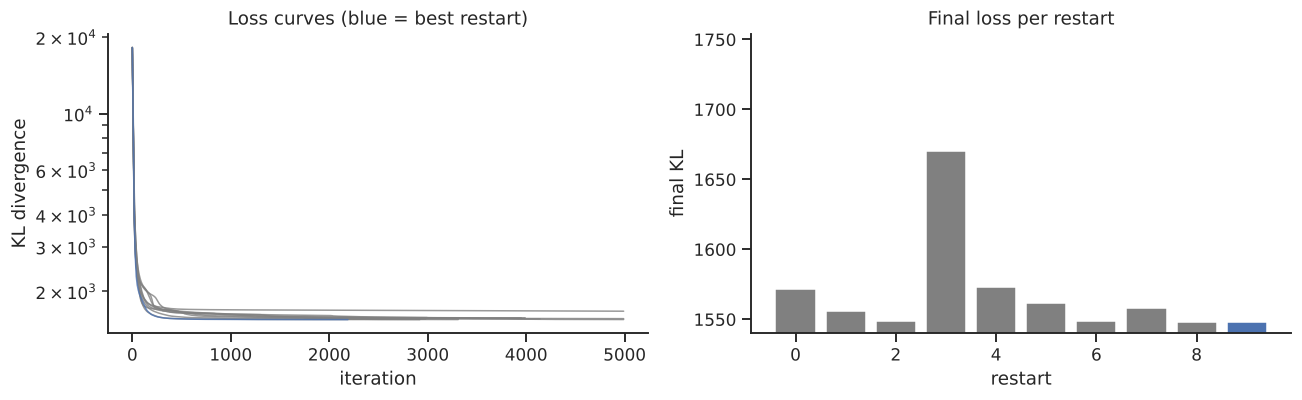

In [5]:
K = W_true.shape[1]
t0 = time.time()
best, runs = fit(X, K)
print(f"K={K}: {N_RESTARTS} restarts in {time.time() - t0:.1f}s; best KL={best['kl']:.1f} after {best['n_iter']} iterations")

# reference: KL of the ground truth itself (noise floor)
print(f"KL of the true W·H: {kl_div(X, W_true.values @ H_true.values):.1f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for d in runs:
    axes[0].plot(np.arange(len(d["losses"])) * 10, d["losses"], lw=1, alpha=0.8, c="C0" if d is best else "grey")
axes[0].set(yscale="log", xlabel="iteration", ylabel="KL divergence", title="Loss curves (blue = best restart)")
axes[1].bar(range(N_RESTARTS), [d["kl"] for d in runs], color=["C0" if d is best else "grey" for d in runs])
axes[1].set(xlabel="restart", ylabel="final KL", title="Final loss per restart", ylim=(min(d["kl"] for d in runs) * 0.995, None))
plt.tight_layout()

### 3.1 Matching recovered to true signatures

Hungarian assignment on cosine similarity (as in the report's Section 3.3), then exposures are compared for the matched pairs.

In [6]:
def cosine_matrix(A, B):
    A = A / np.linalg.norm(A, axis=0, keepdims=True)
    B = B / np.linalg.norm(B, axis=0, keepdims=True)
    return A.T @ B


def match(W_est, W_ref):
    # returns, for each reference signature, the matched estimated column and the cosine
    S = cosine_matrix(np.asarray(W_ref), np.asarray(W_est))
    r, c = linear_sum_assignment(-S)
    return pd.DataFrame({"true": np.asarray(W_ref.columns)[r], "est_col": c, "cosine": S[r, c]})


m = match(best["W"], W_true)
W_est = pd.DataFrame(best["W"][:, m.est_col], index=CHANNELS, columns=m.true)
H_est = pd.DataFrame(best["H"][m.est_col], index=m.true, columns=X.columns)

m["exposure r"] = [np.corrcoef(H_est.loc[s], H_true.loc[s])[0, 1] for s in m.true]
m["true active"] = [(H_true.loc[s] > 0).mean() for s in m.true]
m["true total"] = [H_true.loc[s].sum() for s in m.true]
print(f"mean cosine {m.cosine.mean():.3f}; recovered (cos ≥ {COS_GOOD}): {(m.cosine >= COS_GOOD).sum()}/{K}")
m.sort_values("cosine").drop(columns="est_col").round(3)

mean cosine 0.971; recovered (cos ≥ 0.9): 14/15


,true,cosine,exposure r,true active,true total
12,SBS3,0.770,0.803,0.390,4110.408
2,SBS39,0.927,0.961,0.445,5402.297
14,SBS93,0.930,0.982,0.395,2754.890
5,SBS96,0.983,0.986,0.380,3510.607
6,SBS37,0.988,0.986,0.450,4717.893
0,SBS98,0.989,0.959,0.405,3544.259
8,SBS87,0.992,0.996,0.445,4001.894
1,SBS86,0.996,0.973,0.440,4490.618
13,SBS33,0.998,0.996,0.370,3196.416
11,SBS99,0.998,0.989,0.395,4056.101


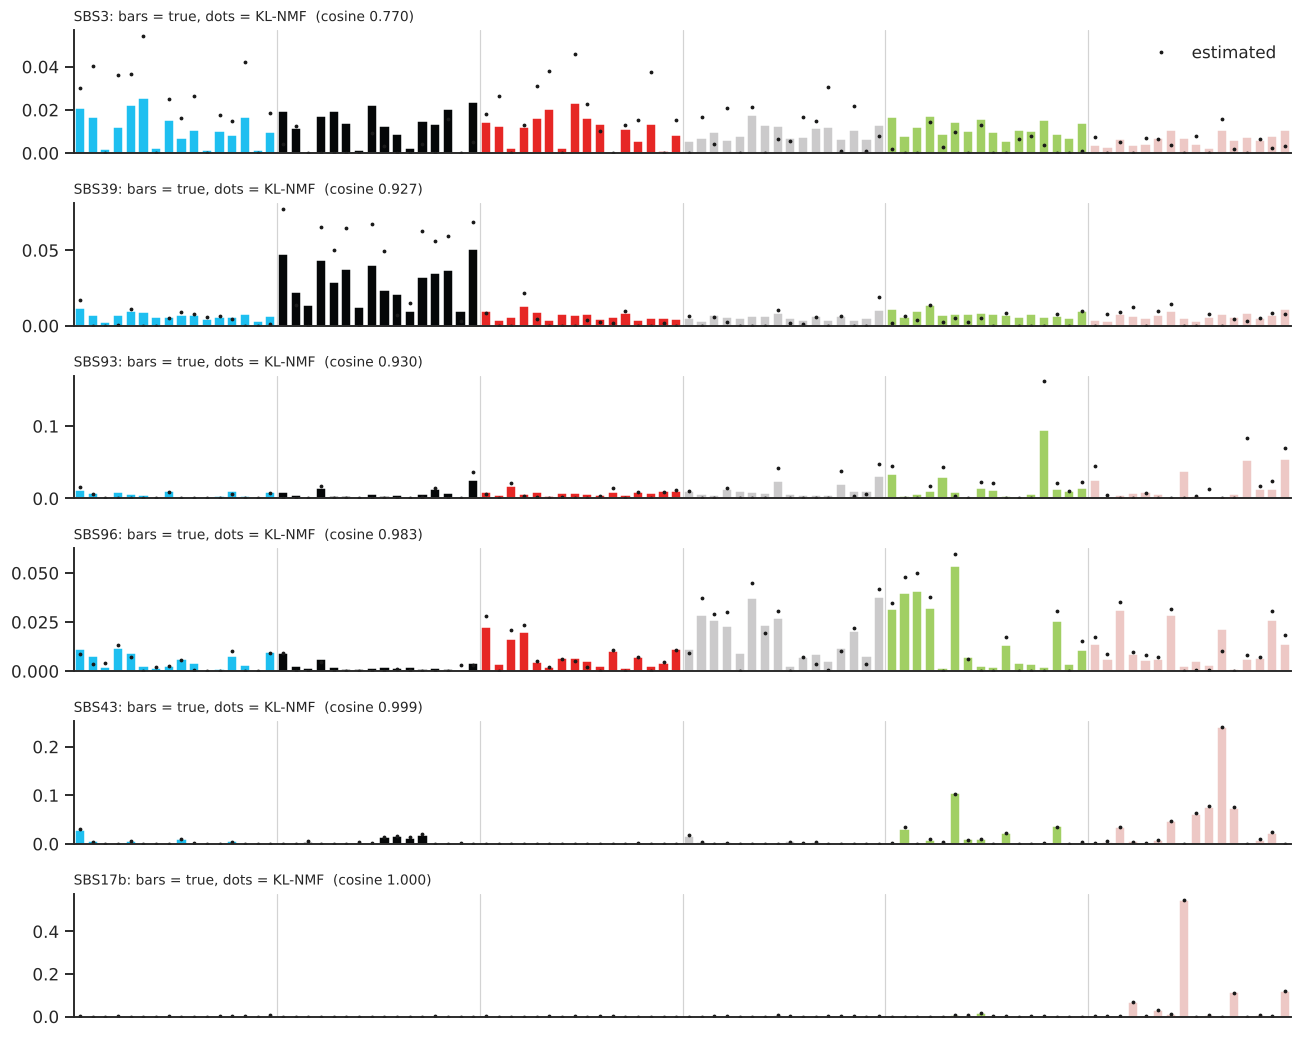

In [7]:
def plot_pair(ax, w_true, w_est, title):
    x = np.arange(96)
    cols = [SUB_COLORS[s] for s in SUB_OF]
    ax.bar(x, w_true, color=cols, width=0.8)
    ax.plot(x, w_est, "k.", ms=3, label="estimated")
    for i in range(1, 6):
        ax.axvline(16 * i - 0.5, c="lightgrey", lw=0.8)
    ax.set_xlim(-0.5, 95.5); ax.set_xticks([])
    ax.set_title(title, fontsize=9, loc="left")

order = m.sort_values("cosine").true.tolist()
show = order[:4] + order[-2:]          # four worst, two best
fig, axes = plt.subplots(len(show), 1, figsize=(12, 1.6 * len(show)), sharex=True)
for ax, s in zip(axes, show):
    plot_pair(ax, W_true[s], W_est[s], f"{s}: bars = true, dots = KL-NMF  (cosine {m.set_index('true').at[s, 'cosine']:.3f})")
axes[0].legend(frameon=False, loc="upper right")
plt.tight_layout()

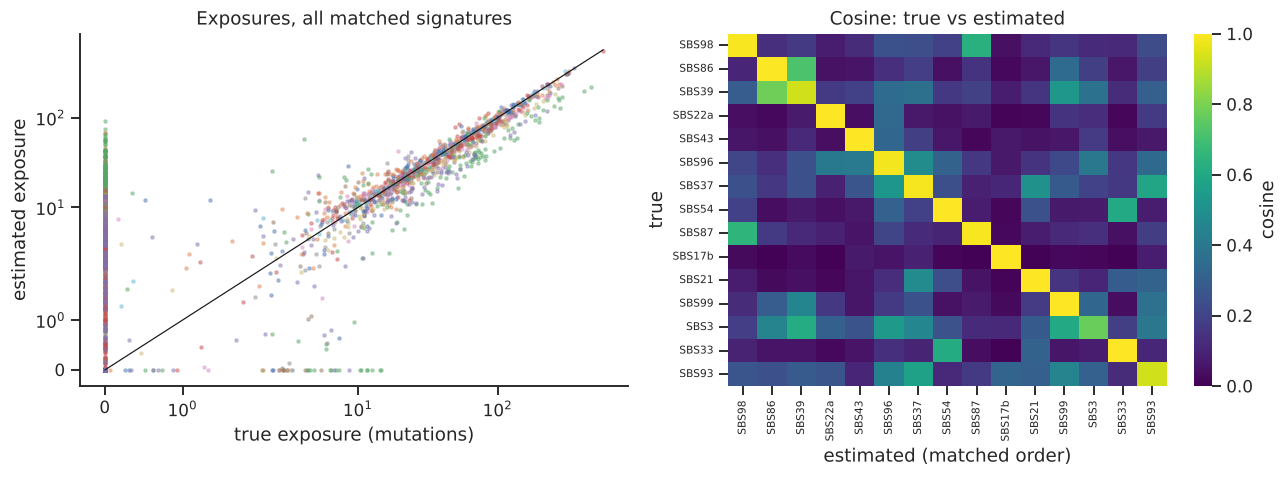

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for s in m.true:
    axes[0].scatter(H_true.loc[s], H_est.loc[s], s=4, alpha=0.4)
lim = max(H_true.values.max(), H_est.values.max())
axes[0].plot([0, lim], [0, lim], c="k", lw=0.8)
axes[0].set(xscale="symlog", yscale="symlog", xlabel="true exposure (mutations)", ylabel="estimated exposure",
            title="Exposures, all matched signatures")

S = cosine_matrix(W_true.values, W_est.values)
sns.heatmap(pd.DataFrame(S, index=W_true.columns, columns=W_est.columns), ax=axes[1], cmap="viridis", vmin=0, vmax=1,
            xticklabels=True, yticklabels=True, cbar_kws={"label": "cosine"})
axes[1].set(xlabel="estimated (matched order)", ylabel="true", title="Cosine: true vs estimated")
axes[1].tick_params(labelsize=7)
plt.tight_layout()

## 4. Rank selection

In practice K is unknown. KL keeps decreasing with K, so the usual criteria are an elbow in the loss and the stability / quality of the extracted signatures. Here the truth is known, so both can be read against it.

,KL,BIC,stability,mean_cos_to_truth,recovered
K,,,,,
12,2045.184,39122.556,0.982,0.981,11
13,1826.226,41603.989,0.970,0.986,12
14,1658.455,44187.797,0.980,0.983,13
15,1548.920,46888.075,0.988,0.971,14
16,1491.534,49692.652,0.984,0.982,15
17,1450.135,52529.204,0.974,0.975,14
18,1408.506,55365.295,0.953,0.979,15


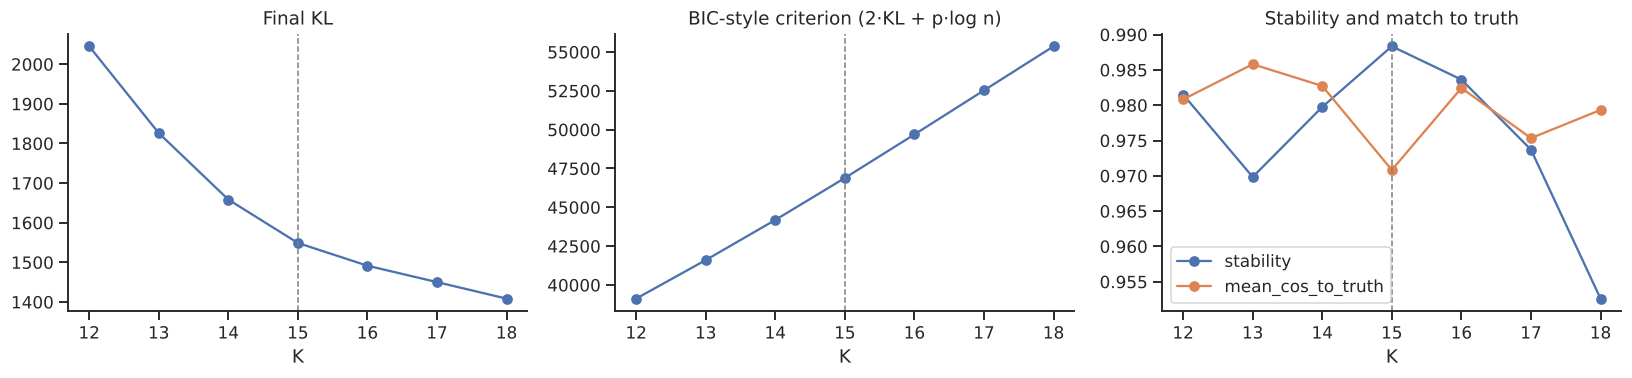

In [9]:
K_GRID = list(range(max(2, K - 3), K + 4))
rows = []
for k in K_GRID:
    b, rr = fit(X, k, n_restarts=3)
    mk = match(b["W"], W_true)
    # stability: mean best-match cosine of every restart's signatures against the best restart's
    stab = np.mean([cosine_matrix(b["W"], d["W"]).max(0).mean() for d in rr if d is not b])
    n_par = k * (96 + X.shape[1])
    rows.append(dict(K=k, KL=b["kl"], BIC=2 * b["kl"] + n_par * np.log(X.size), stability=stab,
                     mean_cos_to_truth=mk.cosine.mean(), recovered=(mk.cosine >= COS_GOOD).sum()))
rank = pd.DataFrame(rows).set_index("K")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
rank.KL.plot(ax=axes[0], marker="o", title="Final KL")
rank.BIC.plot(ax=axes[1], marker="o", title="BIC-style criterion (2·KL + p·log n)")
rank[["stability", "mean_cos_to_truth"]].plot(ax=axes[2], marker="o", title="Stability and match to truth")
for ax in axes:
    ax.axvline(K, c="grey", ls="--", lw=1)
plt.tight_layout()
rank.round(3)

## 5. Recovered vs true signatures under the OT costs

The OT-NMF will be judged by how far its signatures are from the truth in the **ground metric**, not only by cosine. Here the KL-NMF signatures are scored with every cost matrix found in `data/cost_matrix/` (from `03` and `04`): for each matched pair, the entropic OT cost (Sinkhorn) with the cost scaled to max 1. This gives the baseline number the OT-NMF should beat.

In [10]:
def sinkhorn(a, b, C, eps=0.01, n_iter=1000):
    # log-domain Sinkhorn; returns <T, C> for the entropic plan T
    a = a + 1e-12; b = b + 1e-12
    la, lb = np.log(a / a.sum()), np.log(b / b.sum())
    f = np.zeros_like(la); g = np.zeros_like(lb)
    K = -C / eps
    for _ in range(n_iter):
        f = eps * (la - np.logaddexp.reduce(K + g[None, :] / eps, axis=1))
        g = eps * (lb - np.logaddexp.reduce(K + f[:, None] / eps, axis=0))
    return float((np.exp(K + f[:, None] / eps + g[None, :] / eps) * C).sum())


COSTS = {p.stem.removeprefix("C_").removesuffix("_scaled"): pd.read_csv(p, index_col=0).loc[CHANNELS, CHANNELS].values
         for p in sorted((DATA / "cost_matrix").glob("C_*_scaled.csv"))}
print("cost matrices:", list(COSTS) or "none found (run 03 / 04 first)")

if COSTS:
    ot = pd.DataFrame({name: [sinkhorn(W_true[s].values, W_est[s].values, C) for s in m.true] for name, C in COSTS.items()},
                      index=m.true)
    ot["cosine"] = m.set_index("true").cosine
    display(ot.sort_values("cosine").round(4))
    # how well does each OT cost agree with cosine on which signatures are badly recovered?
    display(ot.drop(columns="cosine").corrwith(1 - ot.cosine, method="spearman").rename("Spearman vs 1 - cosine").round(3).to_frame())

cost matrices: ['graph_data', 'graph_energy', 'graph_struct', 'lin_hamming', 'lin_tstv', 'linear']


,graph_data,graph_energy,graph_struct,lin_hamming,lin_tstv,linear,cosine
true,,,,,,,
SBS3,0.1293,0.1381,0.1324,0.2038,0.1453,0.2038,0.7697
SBS39,0.1130,0.0990,0.1151,0.1404,0.1184,0.1404,0.9273
SBS93,0.0986,0.1031,0.1056,0.1448,0.1137,0.1448,0.9297
SBS96,0.0326,0.0325,0.0343,0.0464,0.0365,0.0464,0.9831
SBS37,0.0453,0.0476,0.0465,0.0676,0.0505,0.0676,0.9879
SBS98,0.0434,0.0407,0.0472,0.0662,0.0475,0.0662,0.9893
SBS87,0.0844,0.0853,0.0857,0.1125,0.0876,0.1125,0.9921
SBS86,0.0591,0.0534,0.0608,0.0759,0.0647,0.0759,0.9958
SBS33,0.0447,0.0493,0.0479,0.0662,0.0509,0.0662,0.9979


,Spearman vs 1 - cosine
graph_data,0.879
graph_energy,0.868
graph_struct,0.861
lin_hamming,0.893
lin_tstv,0.868
linear,0.893


## 6. Benchmark over the 9 simulated conditions

K is set to the true number of signatures. Metrics: mean matched cosine, number of true signatures recovered (cosine ≥ `COS_GOOD`), mean exposure correlation, and the relative KL above the ground-truth fit.

In [11]:
bench, fits = [], {}
t0 = time.time()
for k in N_SIGNATURES_LIST:
    for noise in NOISE_LEVELS:
        Xk, Wk, Hk = load(k, noise)
        b, _ = fit(Xk, k, n_restarts=N_RESTARTS_BENCH)
        mk = match(b["W"], Wk)
        He = b["H"][mk.est_col]
        kl_true = kl_div(Xk, Wk.values @ Hk.values)
        fits[(k, noise)] = (b, mk)
        bench.append(dict(k=k, noise=noise, mean_cos=mk.cosine.mean(), min_cos=mk.cosine.min(),
                          recovered=f"{(mk.cosine >= COS_GOOD).sum()}/{k}",
                          exposure_r=np.mean([np.corrcoef(He[i], Hk.loc[s])[0, 1] for i, s in enumerate(mk.true)]),
                          KL=b["kl"], KL_true=kl_true, KL_gap=(b["kl"] - kl_true) / kl_true, iters=b["n_iter"]))
bench = pd.DataFrame(bench)
print(f"benchmark done in {time.time() - t0:.0f}s")
bench.round(3)

benchmark done in 284s


,k,noise,mean_cos,min_cos,recovered,exposure_r,KL,KL_true,KL_gap,iters
0,8,0.02,0.992,0.958,8/8,0.991,1666.140,2022.666,-0.176,1081
1,8,0.04,0.990,0.939,8/8,0.988,1973.454,2472.573,-0.202,1431
2,8,0.06,0.990,0.945,8/8,0.991,2270.903,3070.141,-0.260,1331
3,15,0.02,0.969,0.715,14/15,0.971,1356.254,1820.467,-0.255,4421
4,15,0.04,0.971,0.763,14/15,0.974,1548.920,2139.457,-0.276,3311
5,15,0.06,0.970,0.751,14/15,0.971,1692.478,2456.894,-0.311,3771
6,25,0.02,0.915,0.320,18/25,0.891,1138.163,1749.451,-0.349,5000
7,25,0.04,0.893,0.148,17/25,0.865,1230.584,1938.597,-0.365,5000
8,25,0.06,0.887,0.409,16/25,0.850,1454.993,2394.152,-0.392,5000


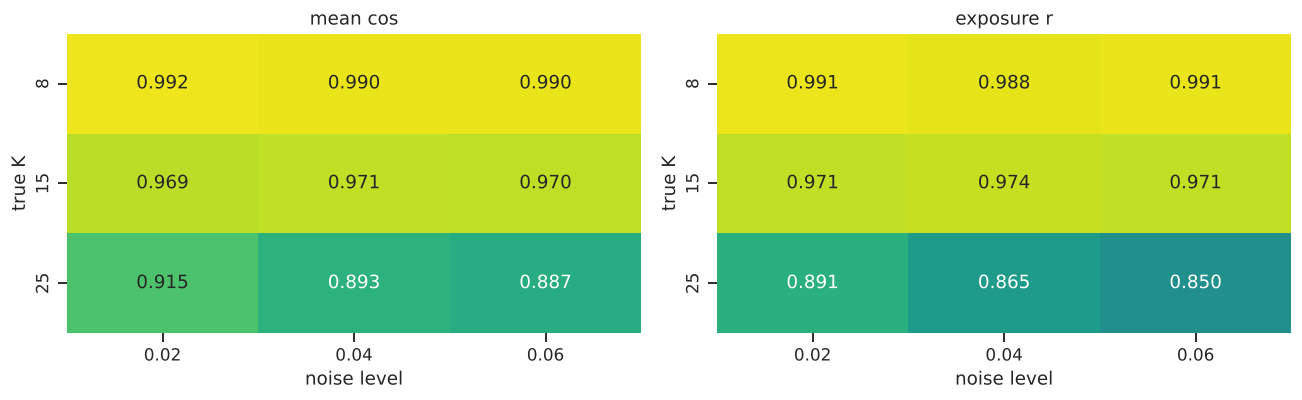

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for metric, ax in zip(["mean_cos", "exposure_r"], axes):
    sns.heatmap(bench.pivot(index="k", columns="noise", values=metric), ax=ax, annot=True, fmt=".3f",
                cmap="viridis", vmin=0.7, vmax=1, cbar=False)
    ax.set(title=metric.replace("_", " "), xlabel="noise level", ylabel="true K")
plt.tight_layout()

**Reading the benchmark**

- `KL_gap` is negative: the fitted $WH$ has a *lower* KL than the true $WH$. The true product lacks the uniform Poisson noise added in `02a`, while the free fit absorbs that noise into the signatures and exposures. This is mild overfitting, and it grows with noise and K.
- Recovery degrades sharply at K = 25: several signatures are only partly recovered, and the solver hits `MAX_ITER`. Mixtures of 25 signatures at medium burden (~50–1,000 SBS per sample) are close to the limit of what 200 samples can identify. This is the regime where an OT loss should help most.
- In §4, the BIC-style criterion simply increases with K, because the parameter count dominates at this sample size. Stability and the loss elbow are the more useful signals.
- In §5, all OT costs rank the poorly recovered signatures the same way cosine does (Spearman ≈ 0.86–0.89). The graph costs give smaller OT distances than the Hamming cost for the same pair, because near-miss mass moves along cheap edges.

## 7. Save

For every condition: `W_<tag>.csv` (96 × K, matched to the true signature names, canonical channel order), `H_<tag>.csv` and the matching table, plus the benchmark summary. These are the KL-NMF baseline for the OT-NMF notebooks.

In [13]:
for (k, noise), (b, mk) in fits.items():
    t = tag(k, noise)
    pd.DataFrame(b["W"][:, mk.est_col], index=CHANNELS, columns=mk.true).to_csv(OUT / f"W_{t}.csv")
    Xk = load(k, noise)[0]
    pd.DataFrame(b["H"][mk.est_col], index=mk.true, columns=Xk.columns).to_csv(OUT / f"H_{t}.csv")
    mk.to_csv(OUT / f"match_{t}.csv", index=False)
bench.to_csv(OUT / "benchmark.csv", index=False)
(OUT / "params.json").write_text(json.dumps({"N_RESTARTS": N_RESTARTS, "N_RESTARTS_BENCH": N_RESTARTS_BENCH, "MAX_ITER": MAX_ITER, "TOL": TOL, "SEED": SEED,
                                             "COS_GOOD": COS_GOOD}, indent=2))
print(OUT); sorted(p.name for p in OUT.iterdir())[:8]

/tmp/claude-0/-home-claude/b0cb3fea-820c-557d-b399-36854fd798b3/scratchpad/work/results/klnmf


['H_k15_noise2pct.csv',
 'H_k15_noise4pct.csv',
 'H_k15_noise6pct.csv',
 'H_k25_noise2pct.csv',
 'H_k25_noise4pct.csv',
 'H_k25_noise6pct.csv',
 'H_k8_noise2pct.csv',
 'H_k8_noise4pct.csv']